# Model 2: logistic regression on IMU features

Each 3 s window is described by a few features from all six IMU channels
(`python/features.py`). A multinomial logistic regression learns a weight per
feature per class. Tested the same way as model 1 and compared side by side.

1. Windows and features
2. Models (model 2, plus model 1 refit on the same folds for comparison)
3. Blocked 5-fold cross-validation
4. Cross-session check
5. Fit on all data, weights, save `model2.json`

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, "../../python")
from features import FS, features

DATA_DIR = Path("../../data")
CLASSES = ["still", "bike", "walk", "run"]
COLS = ["ax", "ay", "az", "gx", "gy", "gz"]
FEATURES = ["rhythm", "dom_hz", "kurtosis", "jerk", "std_gy", "range_amag", "mean_ax"]
WIN_S = 3.0
TRIM_S = 5.0
N_BLOCKS = 5
C = 1.0            # regularisation strength (smaller = simpler weights)

## 1. Windows and features

Same windows as model 1: 3 s, 50% overlap, 5 time blocks per recording,
windows that cross a block edge dropped. Model 1's feature (`ay` peak) is kept
alongside for the comparison.

In [2]:
n = int(WIN_S * FS)
rows = []
for p in sorted(DATA_DIR.glob("*.csv")):
    df = pd.read_csv(p)
    t = (df.t_ms - df.t_ms.iloc[0]) / 1000.0
    x = df.loc[(t >= TRIM_S) & (t <= t.iloc[-1] - TRIM_S), COLS].to_numpy()
    block_of = np.arange(len(x)) * N_BLOCKS // len(x)
    for i in range(0, len(x) - n + 1, n // 2):
        if block_of[i] != block_of[i + n - 1]:
            continue
        w = x[i:i + n]
        ay = w[:, 1]
        rows.append({"rec": p.stem, "label": p.stem.rsplit("_", 1)[0], "block": block_of[i],
                     "peak": np.abs(ay - ay.mean()).max(), **features(w)})
win = pd.DataFrame(rows)
win.groupby("rec").size()

rec
bike_01      37
bike_02      40
run_01       26
still_01     67
walk_01     174
walk_02      52
dtype: int64

## 2. Models

**Model 2**: features are standardised (mean 0, spread 1) so their weights are
comparable, then a multinomial logistic regression. `class_weight="balanced"`
makes every class count equally, like model 1.

**Model 1**: the Gaussian-per-class model from `model1.ipynb`, refit here on
the same folds.

In [3]:
def fit2(df):
    scaler = StandardScaler().fit(df[FEATURES])
    clf = LogisticRegression(C=C, class_weight="balanced", max_iter=2000)
    clf.fit(scaler.transform(df[FEATURES]), df.label)
    return scaler, clf


def predict2(model, df):
    scaler, clf = model
    return clf.predict(scaler.transform(df[FEATURES]))


def fit1(df):
    g = df.groupby("label").peak
    return {c: (g.mean()[c], max(g.std()[c], 0.01)) for c in CLASSES}


def predict1(model, df):
    x = df.peak.to_numpy()[:, None]
    m = np.array([model[c][0] for c in CLASSES])
    s = np.array([model[c][1] for c in CLASSES])
    return np.array(CLASSES)[(-np.log(s) - 0.5 * ((x - m) / s) ** 2).argmax(axis=1)]


MODELS = {"model 1": (fit1, predict1), "model 2": (fit2, predict2)}

## 3. Blocked 5-fold cross-validation

In [4]:
for name, (fit, predict) in MODELS.items():
    win[name] = ""
    for b in range(N_BLOCKS):
        test = win.block == b
        win.loc[test, name] = predict(fit(win[~test]), win[test])


def scores(df, col):
    ok = df[col] == df.label
    recall = ok.groupby(df.label).mean().reindex(CLASSES)
    return pd.Series({"accuracy": ok.mean(), "balanced": recall.mean(), **recall.to_dict()})


cv = pd.DataFrame({name: scores(win, name) for name in MODELS})
cv.map("{:.1%}".format)

,model 1,model 2
accuracy,84.1%,100.0%
balanced,92.2%,100.0%
still,100.0%,100.0%
bike,94.8%,100.0%
walk,73.9%,100.0%
run,100.0%,100.0%


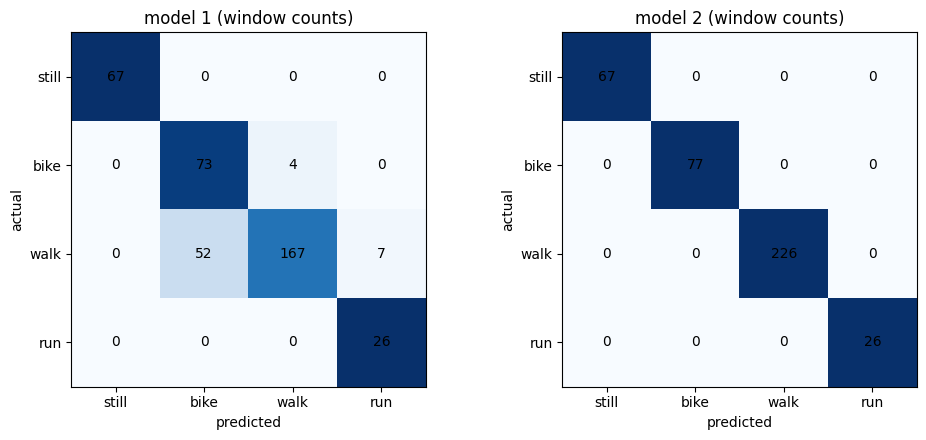

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, name in zip(axs, MODELS):
    conf = pd.crosstab(win.label, win[name]).reindex(index=CLASSES, columns=CLASSES, fill_value=0)
    ax.imshow(conf.div(conf.sum(axis=1), axis=0), cmap="Blues", vmin=0, vmax=1)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, conf.iloc[i, j], ha="center", va="center")
    ax.set_xticks(range(len(CLASSES)), CLASSES)
    ax.set_yticks(range(len(CLASSES)), CLASSES)
    ax.set_xlabel("predicted")
    ax.set_ylabel("actual")
    ax.set_title(f"{name} (window counts)")
fig.tight_layout() 

## 4. Cross-session check

Train with one bike/walk session, test on the other, in both directions.
Still and run (one recording each) are always in training.

In [6]:
PAIRS = {"bike": ("bike_01", "bike_02"), "walk": ("walk_01", "walk_02")}

rows = []
for train_s, test_s in [(0, 1), (1, 0)]:
    test_recs = [PAIRS[c][test_s] for c in PAIRS]
    train, test = win[~win.rec.isin(test_recs)], win[win.rec.isin(test_recs)]
    for name, (fit, predict) in MODELS.items():
        pred = predict(fit(train), test)
        for c in PAIRS:
            mask = (test.label == c).to_numpy()
            rows.append({"test on": f"_0{test_s + 1}", "model": name, "class": c,
                         "recall": (pred[mask] == c).mean()})
xs = pd.DataFrame(rows).pivot_table(index=["test on", "class"], columns="model", values="recall")
xs.map("{:.1%}".format)

model         model 1 model 2
test on class                
_01     bike    86.5%  100.0%
        walk    78.2%   99.4%
_02     bike    65.0%  100.0%
        walk    71.2%  100.0%

## 5. Fit on all data

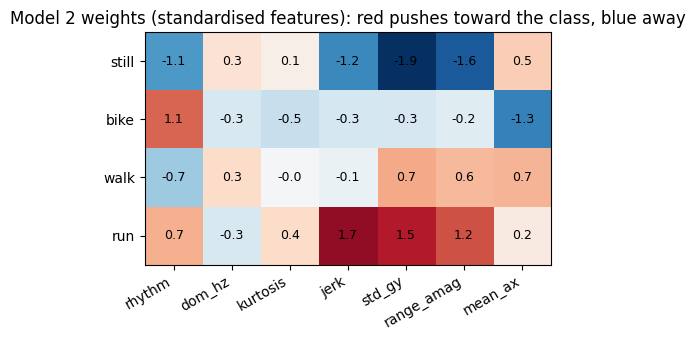

In [7]:
scaler, clf = fit2(win)
weights = pd.DataFrame(clf.coef_, index=clf.classes_, columns=FEATURES).reindex(CLASSES)

fig, ax = plt.subplots(figsize=(9, 3.5))
lim = np.abs(weights.values).max()
ax.imshow(weights, cmap="RdBu_r", vmin=-lim, vmax=lim)
for i in range(len(CLASSES)):
    for j in range(len(FEATURES)):
        ax.text(j, i, f"{weights.iloc[i, j]:.1f}", ha="center", va="center", fontsize=9)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=30, ha="right")
ax.set_yticks(range(len(CLASSES)), CLASSES)
ax.set_title("Model 2 weights (standardised features): red pushes toward the class, blue away")
fig.tight_layout()

In [8]:
out = {
    "fs": FS,
    "window_s": WIN_S,
    "features": FEATURES,
    "classes": list(clf.classes_),
    "scaler_mean": scaler.mean_.round(6).tolist(),
    "scaler_scale": scaler.scale_.round(6).tolist(),
    "coef": clf.coef_.round(6).tolist(),
    "intercept": clf.intercept_.round(6).tolist(),
    "cv": {"accuracy": round(float(cv.loc["accuracy", "model 2"]), 3),
           "recall": {c: round(float(cv.loc[c, "model 2"]), 3) for c in CLASSES}},
}
Path("model2.json").write_text(json.dumps(out, indent=2))
print(json.dumps(out, indent=2))

{
  "fs": 50,
  "window_s": 3.0,
  "features": [
    "rhythm",
    "dom_hz",
    "kurtosis",
    "jerk",
    "std_gy",
    "range_amag",
    "mean_ax"
  ],
  "classes": [
    "bike",
    "run",
    "still",
    "walk"
  ],
  "scaler_mean": [
    0.354527,
    1.710587,
    4.428257,
    9.462729,
    49.824546,
    2.496182,
    -0.103747
  ],
  "scaler_scale": [
    0.240828,
    0.615868,
    2.95708,
    8.506114,
    33.760646,
    1.822009,
    0.342732
  ],
  "coef": [
    [
      1.124078,
      -0.313591,
      -0.450504,
      -0.343283,
      -0.328908,
      -0.233972,
      -1.299431
    ],
    [
      0.686099,
      -0.314565,
      0.361209,
      1.707396,
      1.526755,
      1.224594,
      0.16772
    ],
    [
      -1.103015,
      0.280644,
      0.111503,
      -1.240597,
      -1.92762,
      -1.614897,
      0.481526
    ],
    [
      -0.707163,
      0.347512,
      -0.022208,
      -0.123516,
      0.729774,
      0.624276,
      0.650185
    ]
  ],
  "inter